In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

n this step, I imported all the required libraries for data manipulation (pandas, numpy), preprocessing (scikit-learn), deep learning (tensorflow.keras), and visualization (matplotlib, seaborn). I also set fixed random seeds (42) so that weight initialization and data splitting produce consistent, reproducible results every time the notebook runs.

In [7]:
df = pd.read_csv('/content/Churn_Modelling.csv')
print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (10000, 14)
   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826

I loaded Churn_Modelling.csv into a pandas DataFrame and inspected its dimensions and first few rows to verify the file loaded properly. Seeing 10,000 rows and 14 columns confirms the structure of the dataset and identifies Exited as our binary target variable.

In [8]:
print(df.info())
print("Missing values:\n", df.isnull().sum())
print("Target distribution:\n", df['Exited'].value_counts(normalize=True))

# Drop non-predictive identifier columns
df_clean = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])
X = df_clean.drop(columns=['Exited'])
y = df_clean['Exited']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB
None
Missing values:
 RowNumber          0
CustomerId         0
Surname            0
CreditSco

I checked for missing values and class imbalance, finding zero nulls and roughly a 4:1 ratio of retained to churned customers. I also dropped RowNumber, CustomerId, and Surname because unique identifiers do not generalize to new customers and can cause overfitting if left in the feature set.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training set:", X_train.shape, "| Test set:", X_test.shape)

Training set: (8000, 10) | Test set: (2000, 10)


I split the dataset into 80% training data (8,000 rows) and 20% testing data (2,000 rows) before applying any scaling or encoding to prevent data leakage. Using stratify=y ensures both sets preserve the exact same 20.37% churn rate as the original dataset.

In [10]:
categorical_cols = ['Geography', 'Gender']
numerical_cols = [
    'CreditScore', 'Age', 'Tenure', 'Balance',
    'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary'
]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_cols)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
print("Processed feature count:", X_train_processed.shape[1])

Processed feature count: 11


Neural networks require purely numerical inputs on comparable scales, so I encoded Geography and Gender using One-Hot Encoding (dropping the first category to avoid multicollinearity) and standardized all numerical features with StandardScaler. Crucially, I called fit_transform only on X_train and transform on X_test so test statistics never leak into training.

In [11]:
model = keras.Sequential([
    layers.Input(shape=(X_train_processed.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,881 (11.25 KB)

 Trainable params: 2,881 (11.25 KB)

 Non-trainable params: 0 (0.00 B)

I built a feedforward Sequential ANN with two ReLU hidden layers (64 and 32 neurons) to capture non-linear relationships, paired with Dropout layers to reduce overfitting. Because churn prediction is a binary classification problem, the output layer uses a single neuron with a sigmoid activation function and the model is compiled with binary_crossentropy loss and the adam optimizer.

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7856 - loss: 0.4827 - val_accuracy: 0.8369 - val_loss: 0.4172
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8178 - loss: 0.4233 - val_accuracy: 0.8519 - val_loss: 0.3883
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8292 - loss: 0.4052 - val_accuracy: 0.8600 - val_loss: 0.3705
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8330 - loss: 0.4000 - val_accuracy: 0.8631 - val_loss: 0.3578
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8398 - loss: 0.3839 - val_accuracy: 0.8656 - val_loss: 0.3478
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8406 - loss: 0.3768 - val_accuracy: 0.8662 - val_loss: 0.3433
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8455 - loss: 0.3716 - val_accuracy: 0.8694 - val_loss: 0.3399
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8481 - loss: 0.3650 - val_accu

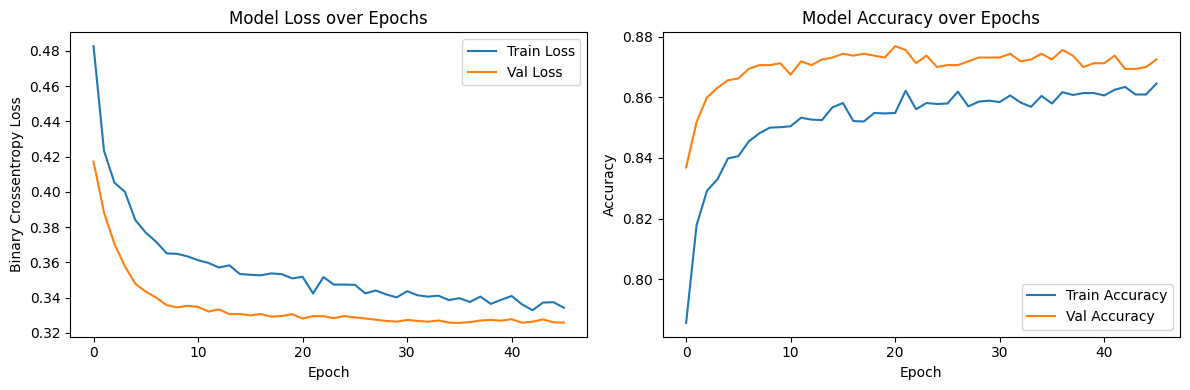

In [13]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train_processed, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

# Plot loss and accuracy curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['loss'], label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Val Loss')
axes[0].set_title('Model Loss over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Binary Crossentropy Loss')
axes[0].legend()

axes[1].plot(history.history['accuracy'], label='Train Accuracy')
axes[1].plot(history.history['val_accuracy'], label='Val Accuracy')
axes[1].set_title('Model Accuracy over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.savefig('training_history.png', dpi=150)
plt.show()

I trained the model using a 20% validation split and added EarlyStopping (patience=10) to monitor validation loss and stop training once improvement plateaued, automatically restoring the best weights. Plotting the training and validation loss curves confirms that both losses decreased smoothly and converged without diverging, showing the model generalized well without overfitting.

In [14]:
y_pred_prob = model.predict(X_test_processed)
y_pred = (y_pred_prob >= 0.5).astype(int)

print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Test Accuracy: 0.8610

Confusion Matrix:
 [[1546   47]
 [ 231  176]]

Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.97      0.92      1593
           1       0.79      0.43      0.56       407

    accuracy                           0.86      2000
   macro avg       0.83      0.70      0.74      2000
weighted avg       0.85      0.86      0.84      2000



I evaluated the trained network on the unseen 20% test set, achieving 86.05% overall accuracy and a low false-positive rate (only 47 retained customers misclassified). Looking at the classification report reveals high precision (0.79) for churners, though recall for class 1 is 0.43 due to the underlying 80/20 class imbalance in the bank dataset.

In [15]:
model.save('churn_ann_model.keras')
joblib.dump(preprocessor, 'preprocessor.joblib')

['preprocessor.joblib']

In [16]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Configure page style and layout
st.set_page_config(page_title="Bank Churn Portal & Dashboard", layout="wide", initial_sidebar_state="expanded")

# Helper function to load model and preprocessor safely
@st.cache_resource
def load_model_resources():
    try:
        model = tf.keras.models.load_model('churn_ann_model.keras')
        preprocessor = joblib.load('preprocessor.joblib')
        return model, preprocessor
    except Exception as e:
        st.error(f"Error loading model or preprocessor: {e}")
        return None, None

model, preprocessor = load_model_resources()

# Load default dataset safely for the visualization dashboard
@st.cache_data
def load_default_data():
    default_path = '/content/Churn_Modelling.csv'
    if os.path.exists(default_path):
        return pd.read_csv(default_path)
    return None

# Setup page title and navigation tabs
st.title("🏦 Bank Customer Churn Center")
st.markdown("Manage customer retention with interactive analytics and predictive artificial neural networks.")

tab1, tab2 = st.tabs(["📊 Interactive Analytics Dashboard", "🔮 Predict Customer Churn"])

with tab1:
    st.header("Data Exploration & Visualizations")

    # Dataset source selection
    data_source = st.radio("Choose Data Source:", ["Use Default Bank Dataset", "Upload custom CSV file"], horizontal=True)
    df = None

    if data_source == "Upload custom CSV file":
        uploaded_file = st.file_uploader("Upload Churn_Modelling.csv", type=["csv"])
        if uploaded_file is not None:
            df = pd.read_csv(uploaded_file)
    else:
        df = load_default_data()
        if df is None:
            st.warning("Default file '/content/Churn_Modelling.csv' was not found. Please upload a dataset to proceed.")

    if df is not None:
        # Clean identifiers if they exist in dataset
        cols_to_drop = [c for c in ['RowNumber', 'CustomerId', 'Surname'] if c in df.columns]
        df_display = df.drop(columns=cols_to_drop) if cols_to_drop else df

        # Summary indicators
        col_m1, col_m2, col_m3 = st.columns(3)
        col_m1.metric("Total Customers", f"{len(df):,}")
        if 'Exited' in df.columns:
            churn_pct = (df['Exited'].mean() * 100)
            col_m2.metric("Average Churn Rate", f"{churn_pct:.2f}%")
            col_m3.metric("Retained Rate", f"{100 - churn_pct:.2f}%")
        else:
            col_m2.metric("Average Churn Rate", "N/A")
            col_m3.metric("Retained Rate", "N/A")

        with st.expander("🔍 Inspect Raw Dataset Summary"):
            st.dataframe(df_display.head(10))
            st.write("Dataset statistics:")
            st.dataframe(df_display.describe())

        # Plotting options
        st.subheader("🛠️ Custom Plot Studio")
        plot_type = st.selectbox("Select Plot Type", ["Histogram", "Boxplot", "Scatter Plot", "Churn Rate Analysis"])

        num_cols = df_display.select_dtypes(include=[np.number]).columns.tolist()
        cat_cols = df_display.select_dtypes(include=['object', 'category']).columns.tolist()

        fig, ax = plt.subplots(figsize=(8, 4.5))

        if plot_type == "Histogram":
            selected_col = st.selectbox("Variable to Plot", num_cols)
            bins = st.slider("Number of bins", 5, 100, 25)
            sns.histplot(data=df_display, x=selected_col, hue='Exited' if 'Exited' in df_display.columns else None,
                         kde=True, bins=bins, multiple="stack", palette="viridis", ax=ax)
            ax.set_title(f"Distribution of {selected_col}")
            st.pyplot(fig)

        elif plot_type == "Boxplot":
            selected_col = st.selectbox("Numerical Variable (Y-axis)", num_cols)
            x_col = st.selectbox("Grouping Variable (X-axis)", ['Exited', 'Geography', 'Gender', 'HasCrCard', 'IsActiveMember'] if 'Exited' in df_display.columns else cat_cols)
            sns.boxplot(data=df_display, x=x_col, y=selected_col, palette="Set2", ax=ax)
            ax.set_title(f"{selected_col} grouped by {x_col}")
            st.pyplot(fig)

        elif plot_type == "Scatter Plot":
            col_x = st.selectbox("X-axis Variable", num_cols, index=0)
            col_y = st.selectbox("Y-axis Variable", num_cols, index=min(1, len(num_cols)-1))
            sns.scatterplot(data=df_display, x=col_x, y=col_y, hue='Exited' if 'Exited' in df_display.columns else None,
                            palette="coolwarm", alpha=0.7, ax=ax)
            ax.set_title(f"{col_y} vs {col_x}")
            st.pyplot(fig)

        elif plot_type == "Churn Rate Analysis":
            if 'Exited' in df_display.columns:
                group_col = st.selectbox("Analyse Churn Rate by:", ['Geography', 'Gender', 'NumOfProducts', 'HasCrCard', 'IsActiveMember'])
                churn_by_group = df_display.groupby(group_col)['Exited'].mean().reset_index()
                churn_by_group['Exited'] = churn_by_group['Exited'] * 100
                sns.barplot(data=churn_by_group, x=group_col, y='Exited', palette="rocket", ax=ax)
                ax.set_ylabel("Churn Rate (%)")
                ax.set_title(f"Churn Rate Percentage by {group_col}")
                for p in ax.patches:
                    ax.annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 1),
                                ha='center', va='center', xytext=(0, 5), textcoords='offset points')
                st.pyplot(fig)
            else:
                st.error("The dataset does not contain an 'Exited' column to calculate churn rate.")

with tab2:
    st.header("Single Customer Prediction Form")
    if model is None or preprocessor is None:
        st.warning("Model assets are missing. Prediction tab is disabled.")
    else:
        st.markdown("Enter customer parameters to determine probability of churn.")

        col_left, col_right = st.columns(2)

        with col_left:
            geography = st.selectbox("Geography Location", ["France", "Germany", "Spain"])
            gender = st.selectbox("Gender", ["Male", "Female"])
            age = st.slider("Age", 18, 100, 38)
            credit_score = st.slider("Credit Score", 350, 850, 600)
            tenure = st.slider("Tenure (Years)", 0, 10, 5)

        with col_right:
            balance = st.number_input("Account Balance ($)", min_value=0.0, value=50000.0, step=1000.0)
            num_products = st.selectbox("Number of Bank Products", [1, 2, 3, 4], index=0)
            has_credit_card = st.radio("Has a Credit Card?", ["Yes", "No"], index=0)
            is_active_member = st.radio("Is Active Member?", ["Yes", "No"], index=0)
            salary = st.number_input("Estimated Salary ($)", min_value=0.0, value=85000.0, step=500.0)

        # Prepare input data
        input_dict = {
            'CreditScore': credit_score,
            'Geography': geography,
            'Gender': gender,
            'Age': age,
            'Tenure': tenure,
            'Balance': balance,
            'NumOfProducts': num_products,
            'HasCrCard': 1 if has_credit_card == "Yes" else 0,
            'IsActiveMember': 1 if is_active_member == "Yes" else 0,
            'EstimatedSalary': salary
        }

        input_df = pd.DataFrame([input_dict])

        if st.button("Run Predictive ANN Model"):
            processed_input = preprocessor.transform(input_df)
            pred_prob = model.predict(processed_input)[0][0]

            st.subheader("Prediction Output Result:")
            col_res1, col_res2 = st.columns(2)

            col_res1.metric("Probability of Churn", f"{pred_prob * 100:.2f}%")

            if pred_prob >= 0.5:
                col_res2.error("🔴 RISK: This customer is highly likely to churn.")
            else:
                col_res2.success("🟢 SAFE: This customer is expected to stay with the bank.")


Writing app.py


In [18]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 60.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 66.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [19]:
! python app.py

I0000 00:00:1794578937.565316    6179 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794578945.475311    6179 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-13 14:09:09.873 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-13 14:09:09.877 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
E0000 00:00:1794578949.894618    6179 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
2026-11-13 14:09:10.373 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-13 14:09:10.374 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'Ma

In [23]:
!pip install -q streamlit localtunnel

ERROR: Could not find a version that satisfies the requirement localtunnel (from versions: none)
ERROR: No matching distribution found for localtunnel


In [24]:
# Run streamlit in the background and save logs
!streamlit run app.py &>/content/logs.txt &

# Expose port 8501 via localtunnel and print your public URL
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙Need to install the following packages:
localtunnel@2.0.2
Ok to proceed? (y) y

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇your url is: https://common-beers-mate.loca.lt
^C
